<a href="https://colab.research.google.com/github/Jovankavania/ets-ml-logisticnetwork/blob/main/reinforcement_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#REINFORCEMENT LEARNING

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
folder = "/content/drive/MyDrive/puskesmas-rute"
folder_aug = os.path.join(folder, "data_augmentation")
folder_rl = os.path.join(folder, "reinforcement_learning")

os.makedirs(folder_rl, exist_ok=True)

# Matriks waktu 20 skenario
matrix_aug = np.load(
    os.path.join(folder_aug, "matrix_time_aug.npy")
)

# Urutan lokasi harus sama dengan matriks
df_lokasi = pd.read_csv(
    os.path.join(folder_aug, "urutan_lokasi_aug.csv")
)

# Kelompok distribusi hasil + penugasan noise
df_kelompok = pd.read_csv(
    os.path.join(folder, "kelompok_agglomerative_k11.csv")
)

# Informasi skenario
df_skenario = pd.read_csv(
    os.path.join(folder_aug, "skenario_traffic.csv")
)

# Rapikan nama untuk pencocokan
df_lokasi["Input Nama"] = df_lokasi["Input Nama"].str.strip()
df_kelompok["Input Nama"] = df_kelompok["Input Nama"].str.strip()

# Cek kesesuaian data
assert matrix_aug.shape == (20, len(df_lokasi), len(df_lokasi))
assert np.isfinite(matrix_aug).all()
assert (matrix_aug >= 0).all()
assert df_lokasi["Input Nama"].is_unique
assert df_kelompok["Input Nama"].is_unique
assert df_kelompok["kelompok_rute"].notna().all()
assert (df_kelompok["kelompok_rute"] != -1).all()

assert df_skenario["skenario"].tolist() == [
    f"S{i:02d}" for i in range(20)
]

# Temukan Dinkes sebagai depot
mask_depot = df_lokasi["Input Nama"].str.contains(
    "Dinas Kesehatan|Dinkes",
    case=False,
    na=False
)

assert mask_depot.sum() == 1

idx_depot = np.flatnonzero(mask_depot.to_numpy())[0]
nama_depot = df_lokasi.loc[idx_depot, "Input Nama"]

# Indeks nama lokasi
indeks_lokasi = {
    nama: i
    for i, nama in enumerate(df_lokasi["Input Nama"])
}

# Semua puskesmas harus terdaftar
assert set(df_kelompok["Input Nama"]) == (
    set(indeks_lokasi) - {nama_depot}
)

# Pembagian skenario
idx_train = np.arange(0, 16)
idx_test = np.arange(16, 20)

print("Ukuran matriks:", matrix_aug.shape)
print("Depot:", nama_depot)
print("Jumlah kelompok:", df_kelompok["kelompok_rute"].nunique())
print("Jumlah puskesmas:", len(df_kelompok))
print("Training:", df_skenario.iloc[idx_train]["skenario"].tolist())
print("Testing:", df_skenario.iloc[idx_test]["skenario"].tolist())

Ukuran matriks: (20, 64, 64)
Depot: Dinas Kesehatan Kota Surabaya
Jumlah kelompok: 11
Jumlah puskesmas: 63
Training: ['S00', 'S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15']
Testing: ['S16', 'S17', 'S18', 'S19']


In [ ]:
#MEMBUAT AGENT

def aksi_valid(posisi, visited, n):
    semua_selesai = (1 << n) - 1

    if visited == semua_selesai:
        return [0]

    return [
        i + 1
        for i in range(n)
        if not (visited & (1 << i))
    ]


def training_qlearning(matrices, episodes=12000, seed=42):

    rng = np.random.default_rng(seed)

    n = matrices.shape[1] - 1

    # Q-table berdasarkan posisi dan status kunjungan
    Q = defaultdict(
        lambda: np.zeros(n + 1, dtype=float)
    )

    reward_episode = []

    alpha = 0.15
    gamma = 1.0

    for ep in range(episodes):

        # Ambil satu skenario secara acak
        idx_skenario = rng.integers(len(matrices))
        C = matrices[idx_skenario]

        posisi = 0
        visited = 0
        total_reward = 0

        # Eksplorasi dikurangi bertahap
        epsilon = 0.05 + 0.85 * (1 - ep / episodes) ** 2

        for langkah in range(n + 1):

            state = (posisi, visited)
            pilihan = aksi_valid(posisi, visited, n)

            # Pilih action
            if rng.random() < epsilon:
                action = int(rng.choice(pilihan))
            else:
                nilai_q = Q[state][pilihan]
                action = int(pilihan[np.argmax(nilai_q)])

            # Reward berdasarkan waktu perjalanan
            waktu = float(C[posisi, action]) / 60
            reward = -waktu

            if action == 0:
                visited_baru = visited
                selesai = True
            else:
                visited_baru = visited | (1 << (action - 1))
                selesai = False

            next_state = (action, visited_baru)

            if selesai:
                nilai_berikutnya = 0
            else:
                pilihan_berikutnya = aksi_valid(
                    action, visited_baru, n
                )

                nilai_berikutnya = np.max(
                    Q[next_state][pilihan_berikutnya]
                )

            # Update Q-value
            target = reward + gamma * nilai_berikutnya

            Q[state][action] += alpha * (
                target - Q[state][action]
            )

            total_reward += reward

            posisi = action
            visited = visited_baru

            if selesai:
                break

        reward_episode.append(total_reward)

    return Q, reward_episode

In [ ]:
#MENGAMBIL RUTE AGENT DAN BASELINE
def ambil_rute_q(Q, n):

    posisi = 0
    visited = 0

    rute = [0]

    for langkah in range(n + 1):

        state = (posisi, visited)
        pilihan = aksi_valid(posisi, visited, n)

        nilai_q = Q[state][pilihan]
        action = int(pilihan[np.argmax(nilai_q)])

        rute.append(action)

        if action == 0:
            break

        visited |= 1 << (action - 1)
        posisi = action

    assert len(rute) == n + 2
    assert set(rute[1:-1]) == set(range(1, n + 1))

    return rute


def nearest_neighbor(C):

    n = C.shape[0] - 1

    belum = set(range(1, n + 1))
    rute = [0]

    while belum:

        posisi = rute[-1]

        tujuan = min(
            belum,
            key=lambda j: (C[posisi, j], j)
        )

        rute.append(tujuan)
        belum.remove(tujuan)

    rute.append(0)

    return rute


def hitung_waktu_rute(C, rute):

    total_detik = sum(
        C[a, b]
        for a, b in zip(rute[:-1], rute[1:])
    )

    return float(total_detik / 60)

In [ ]:
#TRAINING RL
hasil_evaluasi = []
hasil_rute = []
hasil_training = []

episodes = 12000

for no, (cluster, grup) in enumerate(
    df_kelompok.groupby("kelompok_rute", sort=True),
    start=1
):

    nama_anggota = grup["Input Nama"].tolist()
    n = len(nama_anggota)

    if n > 12:
      raise ValueError(
          f"Kelompok {cluster} punya {n} puskesmas. "
          "Melebihi batas maksimal 12 anggota."
          )

    # Indeks Dinkes dan anggota cluster
    idx_lokasi = [idx_depot] + [
        indeks_lokasi[nama]
        for nama in nama_anggota
    ]

    # Matriks 20 skenario untuk kelompok ini
    matrices = matrix_aug[:, idx_lokasi, :][:, :, idx_lokasi]

    print(
        f"Training kelompok {cluster} "
        f"({no}/{df_kelompok['kelompok_rute'].nunique()}), "
        f"anggota: {n}"
    )

    # RL tanpa augmentation, hanya kondisi normal
    Q_normal, reward_normal = training_qlearning(
        matrices[[0]],
        episodes=episodes,
        seed=100 + no
    )

    # RL dengan 16 skenario augmentation
    Q_aug, reward_aug = training_qlearning(
        matrices[idx_train],
        episodes=episodes,
        seed=100 + no
    )

    # Ambil urutan rute masing-masing model
    rute_normal = ambil_rute_q(Q_normal, n)
    rute_aug = ambil_rute_q(Q_aug, n)

    # Nearest Neighbor menggunakan rata-rata training
    C_rata = matrices[idx_train].mean(axis=0)
    rute_nn = nearest_neighbor(C_rata)

    kumpulan_rute = {
        "RL Normal": rute_normal,
        "RL Augmentation": rute_aug,
        "Nearest Neighbor": rute_nn
    }

    # Simpan urutan kunjungan
    for metode, rute in kumpulan_rute.items():

        nama_rute = [nama_depot] + [
            nama_anggota[i - 1]
            for i in rute[1:-1]
        ] + [nama_depot]

        hasil_rute.append({
            "kelompok_rute": cluster,
            "metode": metode,
            "jumlah_puskesmas": n,
            "rute": " -> ".join(nama_rute)
        })

    # Evaluasi pada 4 skenario yang tidak dilatih
    for idx in idx_test:

        C = matrices[idx]

        for metode, rute in kumpulan_rute.items():

            waktu_menit = hitung_waktu_rute(C, rute)

            hasil_evaluasi.append({
                "kelompok_rute": cluster,
                "skenario": df_skenario.loc[idx, "skenario"],
                "metode": metode,
                "jumlah_puskesmas": n,
                "waktu_menit": waktu_menit
            })

    # Perbandingan reward pada awal dan akhir training
    for metode, rewards in [
        ("RL Normal", reward_normal),
        ("RL Augmentation", reward_aug)
    ]:
        hasil_training.append({
            "kelompok_rute": cluster,
            "metode": metode,
            "reward_awal": np.mean(rewards[:500]),
            "reward_akhir": np.mean(rewards[-500:])
        })

print("\nTraining semua kelompok selesai.")

Training kelompok 0 (1/11), anggota: 6
Training kelompok 1 (2/11), anggota: 4
Training kelompok 2 (3/11), anggota: 9
Training kelompok 3 (4/11), anggota: 8
Training kelompok 4 (5/11), anggota: 8
Training kelompok 5 (6/11), anggota: 6
Training kelompok 6 (7/11), anggota: 4
Training kelompok 7 (8/11), anggota: 3
Training kelompok 8 (9/11), anggota: 4
Training kelompok 9 (10/11), anggota: 2
Training kelompok 10 (11/11), anggota: 9

Training semua kelompok selesai.


In [ ]:
#MENYIMPAN RL

df_hasil = pd.DataFrame(hasil_evaluasi)
df_rute = pd.DataFrame(hasil_rute)
df_training = pd.DataFrame(hasil_training)

# Simpan hasil
df_hasil.to_csv(
    os.path.join(folder_rl, "hasil_evaluasi_rl.csv"),
    index=False
)

df_rute.to_csv(
    os.path.join(folder_rl, "hasil_rute_rl.csv"),
    index=False
)

df_training.to_csv(
    os.path.join(folder_rl, "hasil_training_rl.csv"),
    index=False
)

# Rata-rata waktu per kelompok
ringkasan = (
    df_hasil.groupby("metode")["waktu_menit"]
    .agg(["mean", "min", "max"])
    .round(2)
)

print("Ringkasan waktu perjalanan per kelompok:")
display(ringkasan)

# Jumlah seluruh waktu rute pada tiap skenario
total_skenario = (
    df_hasil.groupby(["skenario", "metode"])["waktu_menit"]
    .sum()
    .unstack()
)

total_skenario["perbaikan_vs_nn_pct"] = (
    (
        total_skenario["Nearest Neighbor"]
        - total_skenario["RL Augmentation"]
    )
    / total_skenario["Nearest Neighbor"]
) * 100

print("\nTotal waktu seluruh kelompok per skenario:")
display(total_skenario.round(2))

print("\nPerubahan reward selama training:")
display(df_training.round(2))

print("\nContoh urutan kunjungan:")
display(df_rute.head(6))

Ringkasan waktu perjalanan per kelompok:


,mean,min,max
metode,,,
Nearest Neighbor,56.26,26.57,81.13
RL Augmentation,60.61,26.57,105.62
RL Normal,58.91,26.57,99.74



Total waktu seluruh kelompok per skenario:


metode,Nearest Neighbor,RL Augmentation,RL Normal,perbaikan_vs_nn_pct
skenario,,,,
S16,538.26,575.42,557.82,-6.90
S17,631.72,682.02,663.13,-7.96
S18,601.13,651.12,634.09,-8.32
S19,704.35,758.30,736.80,-7.66



Perubahan reward selama training:


,kelompok_rute,metode,reward_awal,reward_akhir
0,0,RL Normal,-50.00,-39.14
1,0,RL Augmentation,-55.27,-42.72
2,1,RL Normal,-45.39,-39.63
3,1,RL Augmentation,-50.04,-43.80
4,2,RL Normal,-68.44,-66.22
5,2,RL Augmentation,-75.97,-74.44
6,3,RL Normal,-60.76,-58.45
7,3,RL Augmentation,-66.84,-64.32
8,4,RL Normal,-66.38,-63.53
9,4,RL Augmentation,-73.06,-70.42



Contoh urutan kunjungan:


,kelompok_rute,metode,jumlah_puskesmas,rute
0,0,RL Normal,6,Dinas Kesehatan Kota Surabaya -> Puskesmas Kla...
1,0,RL Augmentation,6,Dinas Kesehatan Kota Surabaya -> Puskesmas Kla...
2,0,Nearest Neighbor,6,Dinas Kesehatan Kota Surabaya -> Puskesmas Ten...
3,1,RL Normal,4,Dinas Kesehatan Kota Surabaya -> Puskesmas Wiy...
4,1,RL Augmentation,4,Dinas Kesehatan Kota Surabaya -> Puskesmas Wiy...
5,1,Nearest Neighbor,4,Dinas Kesehatan Kota Surabaya -> Puskesmas Ked...


#TUNING RL

In [ ]:
# Parameter tuning ringan
episode_v2 = [12000, 24000]
alpha_v2 = [0.10]
seed_v2 = [42]

# Skenario training
skenario_v2 = {
    "S00": [0],
    "S00-S11": list(range(12))
}

# Data validasi dan testing
idx_validasi_v2 = [12, 13, 14, 15]
idx_testing_v2 = [16, 17, 18, 19]

# Matriks masing-masing kelompok
matriks_kelompok_v2 = {}

for cluster, grup in df_kelompok.groupby(
    "kelompok_rute", sort=True
):

    nama_anggota = grup["Input Nama"].tolist()

    idx_lokasi = [idx_depot] + [
        indeks_lokasi[nama]
        for nama in nama_anggota
    ]

    matriks_kelompok_v2[cluster] = matrix_aug[
        :, idx_lokasi, :
    ][:, :, idx_lokasi]

assert len(matriks_kelompok_v2) == 11

assert sum(
    C.shape[1] - 1
    for C in matriks_kelompok_v2.values()
) == 63

total_training = (
    len(episode_v2)
    * len(alpha_v2)
    * len(seed_v2)
    * len(skenario_v2)
    * len(matriks_kelompok_v2)
)

print("Jumlah kelompok:", len(matriks_kelompok_v2))
print("Jumlah kombinasi training:", total_training)
print("Episode:", episode_v2)
print("Alpha:", alpha_v2)
print("Seed:", seed_v2)

Jumlah kelompok: 11
Jumlah kombinasi training: 44
Episode: [12000, 24000]
Alpha: [0.1]
Seed: [42]


In [ ]:
def training_qlearning_v2(matrices, episodes, alpha, seed):

    rng = np.random.default_rng(seed)

    n = matrices.shape[1] - 1

    Q = defaultdict(
        lambda: np.zeros(n + 1, dtype=float)
    )

    gamma = 1.0
    reward_episode = []

    # Rata-rata waktu dari data training saja
    C_rata = matrices.mean(axis=0)

    rute_terbaik = None
    waktu_terbaik = float("inf")

    for ep in range(episodes):

        # Pilih skenario training secara acak
        idx_skenario = rng.integers(len(matrices))
        C = matrices[idx_skenario]

        posisi = 0
        visited = 0
        total_reward = 0

        # Epsilon turun secara linear
        epsilon = 0.05 + 0.85 * (1 - ep / episodes)

        for langkah in range(n + 1):

            state = (posisi, visited)

            pilihan = aksi_valid(posisi, visited, n)

            if rng.random() < epsilon:

                action = int(rng.choice(pilihan))

            else:

                nilai_q = Q[state][pilihan]

                # Acak jika beberapa action memiliki nilai sama
                nilai_max = np.max(nilai_q)

                kandidat = [
                    a for a, q in zip(pilihan, nilai_q)
                    if np.isclose(q, nilai_max)
                ]

                action = int(rng.choice(kandidat))

            # Reward negatif waktu perjalanan
            waktu = float(C[posisi, action]) / 60
            reward = -waktu

            if action == 0:
                visited_baru = visited
                selesai = True
            else:
                visited_baru = visited | (1 << (action - 1))
                selesai = False

            next_state = (action, visited_baru)

            if selesai:
                nilai_berikutnya = 0
            else:
                pilihan_berikutnya = aksi_valid(
                    action, visited_baru, n
                )

                nilai_berikutnya = np.max(
                    Q[next_state][pilihan_berikutnya]
                )

            target = reward + gamma * nilai_berikutnya

            Q[state][action] += alpha * (
                target - Q[state][action]
            )

            total_reward += reward

            posisi = action
            visited = visited_baru

            if selesai:
                break

        reward_episode.append(total_reward)

        # Periksa rute greedy setiap 2000 episode
        if (ep + 1) % 4000 == 0 or ep == episodes - 1:

            rute_sekarang = ambil_rute_q(Q, n)

            waktu_sekarang = hitung_waktu_rute(
                C_rata,
                rute_sekarang
            )

            # Simpan rute checkpoint terbaik
            if waktu_sekarang < waktu_terbaik:

                waktu_terbaik = waktu_sekarang
                rute_terbaik = rute_sekarang.copy()

    # Rute yang dihasilkan Q-table paling akhir
    rute_akhir = ambil_rute_q(Q, n)

    return rute_terbaik, rute_akhir, reward_episode

In [ ]:
hasil_tuning_v2 = []

path_detail_v2 = os.path.join(
    folder_rl, "tuning_rl_v2_detail_agg_k11.csv"
)

for nama_data, idx_data in skenario_v2.items():

    for episodes in episode_v2:

        for alpha in alpha_v2:

            for seed in seed_v2:

                print(
                    f"Training {nama_data}, "
                    f"{episodes} episode, "
                    f"alpha={alpha}, seed={seed}"
                )

                for cluster, matrices in matriks_kelompok_v2.items():

                    n = matrices.shape[1] - 1

                    # Data training sesuai konfigurasi
                    C_train = matrices[idx_data]

                    # RL dilatih dengan data tersebut
                    rute_checkpoint, rute_akhir, rewards = (
                        training_qlearning_v2(
                            C_train,
                            episodes=episodes,
                            alpha=alpha,
                            seed=seed
                        )
                    )

                    # NN menggunakan rata-rata data yang sama
                    C_rata = C_train.mean(axis=0)

                    rute_nn = nearest_neighbor(C_rata)

                    daftar_rute = {
                        "RL Checkpoint": rute_checkpoint,
                        "RL Akhir": rute_akhir,
                        "NN Setara": rute_nn
                    }

                    # Evaluasi dengan S12-S15
                    for idx in idx_validasi_v2:

                        C_validasi = matrices[idx]

                        for metode, rute in daftar_rute.items():

                            waktu = hitung_waktu_rute(
                                C_validasi, rute
                            )

                            hasil_tuning_v2.append({
                                "data_training": nama_data,
                                "episodes": episodes,
                                "alpha": alpha,
                                "seed": seed,
                                "kelompok_rute": cluster,
                                "skenario": f"S{idx:02d}",
                                "metode": metode,
                                "waktu_menit": waktu
                            })

                # Simpan hasil sementara setiap konfigurasi
                pd.DataFrame(hasil_tuning_v2).to_csv(
                    path_detail_v2,
                    index=False
                )

                print("Selesai.\n")

print("Seluruh tuning kedua selesai.")

Training S00, 12000 episode, alpha=0.1, seed=42
Selesai.

Training S00, 24000 episode, alpha=0.1, seed=42
Selesai.

Training S00-S11, 12000 episode, alpha=0.1, seed=42
Selesai.

Training S00-S11, 24000 episode, alpha=0.1, seed=42
Selesai.

Seluruh tuning kedua selesai.


In [ ]:
df_tuning_v2 = pd.DataFrame(hasil_tuning_v2)

# Jumlahkan waktu semua kelompok untuk setiap skenario
df_total_v2 = (
    df_tuning_v2.groupby(
        [
            "data_training",
            "episodes",
            "alpha",
            "seed",
            "skenario",
            "metode"
        ]
    )["waktu_menit"]
    .sum()
    .unstack("metode")
    .reset_index()
)

# Rata-rata dari 2 seed dan 4 skenario validasi
df_ringkasan_v2 = (
    df_total_v2.groupby(
        ["data_training", "episodes", "alpha"]
    )
    .agg(
        waktu_rl=("RL Checkpoint", "mean"),
        waktu_rl_akhir=("RL Akhir", "mean"),
        waktu_nn=("NN Setara", "mean"),
        std_rl=("RL Checkpoint", "std")
    )
    .reset_index()
)

# Persentase penghematan RL terhadap NN
df_ringkasan_v2["hemat_vs_nn_persen"] = (
    (
        df_ringkasan_v2["waktu_nn"]
        - df_ringkasan_v2["waktu_rl"]
    )
    / df_ringkasan_v2["waktu_nn"]
) * 100

# Positif berarti RL lebih cepat daripada NN
df_ringkasan_v2 = df_ringkasan_v2.sort_values(
    "waktu_rl"
).reset_index(drop=True)

print("=== HASIL TUNING Q-LEARNING KEDUA ===")
display(df_ringkasan_v2.round(3))

print("\nKonfigurasi yang berhasil mengungguli NN:")
display(
    df_ringkasan_v2[
        df_ringkasan_v2["hemat_vs_nn_persen"] > 0
    ].round(3)
)

df_ringkasan_v2.to_csv(
    os.path.join(
        folder_rl, "tuning_rl_v2_ringkasan_agg_k11.csv"
    ),
    index=False
)

=== HASIL TUNING Q-LEARNING KEDUA ===


,data_training,episodes,alpha,waktu_rl,waktu_rl_akhir,waktu_nn,std_rl,hemat_vs_nn_persen
0,S00,24000,0.1,585.256,644.821,602.302,85.772,2.830
1,S00-S11,24000,0.1,593.364,635.432,602.302,86.954,1.484
2,S00,12000,0.1,612.809,632.258,602.302,89.689,-1.744
3,S00-S11,12000,0.1,618.850,639.727,602.302,90.740,-2.747



Konfigurasi yang berhasil mengungguli NN:


,data_training,episodes,alpha,waktu_rl,waktu_rl_akhir,waktu_nn,std_rl,hemat_vs_nn_persen
0,S00,24000,0.1,585.256,644.821,602.302,85.772,2.830
1,S00-S11,24000,0.1,593.364,635.432,602.302,86.954,1.484


In [ ]:
# Bandingkan hasil tuning dengan NN
df_banding = df_ringkasan_v2[
    [
        "data_training",
        "episodes",
        "alpha",
        "waktu_rl",
        "waktu_nn",
        "hemat_vs_nn_persen"
    ]
].copy()

df_banding["selisih_menit"] = (
    df_banding["waktu_nn"]
    - df_banding["waktu_rl"]
)

df_banding["hasil"] = np.where(
    df_banding["selisih_menit"] > 0,
    "RL lebih cepat",
    np.where(
        df_banding["selisih_menit"] < 0,
        "NN lebih cepat",
        "Sama"
    )
)

display(
    df_banding.sort_values(
        "waktu_rl"
    ).round(3)
)

,data_training,episodes,alpha,waktu_rl,waktu_nn,hemat_vs_nn_persen,selisih_menit,hasil
0,S00,24000,0.1,585.256,602.302,2.830,17.047,RL lebih cepat
1,S00-S11,24000,0.1,593.364,602.302,1.484,8.939,RL lebih cepat
2,S00,12000,0.1,612.809,602.302,-1.744,-10.507,NN lebih cepat
3,S00-S11,12000,0.1,618.850,602.302,-2.747,-16.548,NN lebih cepat


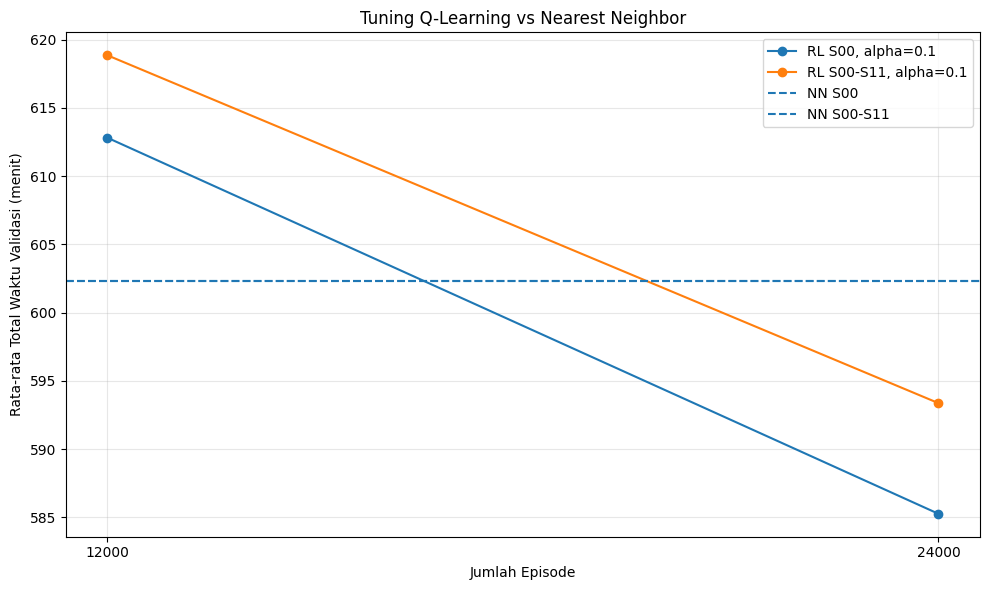

In [ ]:
plt.figure(figsize=(10, 6))

for nama_data in skenario_v2:

    for alpha in alpha_v2:

        data = df_ringkasan_v2[
            (df_ringkasan_v2["data_training"] == nama_data) &
            (df_ringkasan_v2["alpha"] == alpha)
        ].sort_values("episodes")

        plt.plot(
            data["episodes"],
            data["waktu_rl"],
            marker="o",
            label=f"RL {nama_data}, alpha={alpha}"
        )

# Garis baseline NN untuk masing-masing data training
for nama_data in skenario_v2:

    data = df_ringkasan_v2[
        df_ringkasan_v2["data_training"] == nama_data
    ].sort_values("episodes")

    nn_rata = data["waktu_nn"].mean()

    plt.axhline(
        nn_rata,
        linestyle="--",
        label=f"NN {nama_data}"
    )

plt.xlabel("Jumlah Episode")
plt.ylabel("Rata-rata Total Waktu Validasi (menit)")
plt.title("Tuning Q-Learning vs Nearest Neighbor")
plt.xticks(episode_v2)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        folder_rl, "grafik_tuning_rl_v2_agg_k11.png"
    ),
    dpi=150
)

plt.show()

In [ ]:
terbaik_v2 = df_ringkasan_v2.iloc[0]

data_terbaik = terbaik_v2["data_training"]
episode_terbaik = int(terbaik_v2["episodes"])
alpha_terbaik = float(terbaik_v2["alpha"])

idx_train_terbaik = skenario_v2[data_terbaik]

print("=== KONFIGURASI TERBAIK ===")

print("Data training:", data_terbaik)
print("Episode:", episode_terbaik)
print("Alpha:", alpha_terbaik)

print(
    "Rata-rata total waktu RL:",
    round(terbaik_v2["waktu_rl"], 2),
    "menit"
)

print(
    "Rata-rata total waktu NN setara:",
    round(terbaik_v2["waktu_nn"], 2),
    "menit"
)

print(
    "Penghematan terhadap NN:",
    round(terbaik_v2["hemat_vs_nn_persen"], 2),
    "%"
)

=== KONFIGURASI TERBAIK ===
Data training: S00
Episode: 24000
Alpha: 0.1
Rata-rata total waktu RL: 585.26 menit
Rata-rata total waktu NN setara: 602.3 menit
Penghematan terhadap NN: 2.83 %


In [ ]:
hasil_testing_v2 = []
hasil_rute_v2 = []

for seed in seed_v2:

    print("Testing seed:", seed)

    for cluster, grup in df_kelompok.groupby(
        "kelompok_rute", sort=True
    ):

        nama_anggota = grup["Input Nama"].tolist()

        matrices = matriks_kelompok_v2[cluster]

        n = matrices.shape[1] - 1

        C_train = matrices[idx_train_terbaik]

        # Training ulang Q-Learning terbaik
        rute_checkpoint, rute_akhir, rewards = (
            training_qlearning_v2(
                C_train,
                episodes=episode_terbaik,
                alpha=alpha_terbaik,
                seed=seed
            )
        )

        # NN mendapatkan data training yang sama
        C_rata = C_train.mean(axis=0)
        rute_nn = nearest_neighbor(C_rata)

        daftar_rute = {
            "RL Checkpoint": rute_checkpoint,
            "RL Akhir": rute_akhir,
            "NN Setara": rute_nn
        }

        # Simpan urutan kunjungan
        for metode, rute in daftar_rute.items():

            nama_rute = [nama_depot] + [
                nama_anggota[i - 1]
                for i in rute[1:-1]
            ] + [nama_depot]

            hasil_rute_v2.append({
                "seed": seed,
                "kelompok_rute": cluster,
                "metode": metode,
                "rute": " -> ".join(nama_rute)
            })

        # Testing S16-S19
        for idx in idx_testing_v2:

            C_test = matrices[idx]

            for metode, rute in daftar_rute.items():

                waktu = hitung_waktu_rute(
                    C_test, rute
                )

                hasil_testing_v2.append({
                    "seed": seed,
                    "kelompok_rute": cluster,
                    "skenario": f"S{idx:02d}",
                    "metode": metode,
                    "waktu_menit": waktu
                })

print("\nTesting selesai.")

Testing seed: 42

Testing selesai.


In [ ]:
df_testing_v2 = pd.DataFrame(hasil_testing_v2)
df_rute_v2 = pd.DataFrame(hasil_rute_v2)

# Total waktu semua kelompok
df_total_test_v2 = (
    df_testing_v2.groupby(
        ["seed", "skenario", "metode"]
    )["waktu_menit"]
    .sum()
    .unstack("metode")
    .reset_index()
)

# Bandingkan RL dengan NN
df_total_test_v2["hemat_vs_nn_persen"] = (
    (
        df_total_test_v2["NN Setara"]
        - df_total_test_v2["RL Checkpoint"]
    )
    / df_total_test_v2["NN Setara"]
) * 100

print("=== HASIL TESTING PER SEED DAN SKENARIO ===")
display(df_total_test_v2.round(2))

# Rata-rata total waktu berdasarkan metode
df_rata_test_v2 = (
    df_total_test_v2[
        ["RL Checkpoint", "RL Akhir", "NN Setara"]
    ]
    .mean()
)

print("\n=== RATA-RATA TOTAL WAKTU TESTING ===")
display(df_rata_test_v2.round(2))

waktu_rl = df_rata_test_v2["RL Checkpoint"]
waktu_nn = df_rata_test_v2["NN Setara"]

hemat_persen = (
    (waktu_nn - waktu_rl) / waktu_nn
) * 100

print("\nPerbandingan hasil akhir:")

if hemat_persen > 0:
    print(
        f"Q-Learning lebih cepat {hemat_persen:.2f}% "
        "dibandingkan NN."
    )
elif hemat_persen < 0:
    print(
        f"Q-Learning masih lebih lambat "
        f"{abs(hemat_persen):.2f}% dibandingkan NN."
    )
else:
    print("Q-Learning dan NN menghasilkan waktu yang sama.")

# Simpan hasil
df_testing_v2.to_csv(
    os.path.join(
        folder_rl, "testing_rl_v2_detail_agg_k11.csv"
    ),
    index=False
)

df_total_test_v2.to_csv(
    os.path.join(
        folder_rl, "testing_rl_v2_total_agg_k11.csv"
    ),
    index=False
)

df_rute_v2.to_csv(
    os.path.join(
        folder_rl, "rute_rl_v2_agg_k11.csv"
    ),
    index=False
)

=== HASIL TESTING PER SEED DAN SKENARIO ===


metode,seed,skenario,NN Setara,RL Akhir,RL Checkpoint,hemat_vs_nn_persen
0,42,S16,538.26,571.50,521.39,3.13
1,42,S17,631.72,679.55,615.11,2.63
2,42,S18,601.13,649.05,587.57,2.26
3,42,S19,704.35,754.15,684.65,2.80



=== RATA-RATA TOTAL WAKTU TESTING ===


,0
metode,
RL Checkpoint,602.18
RL Akhir,663.56
NN Setara,618.87



Perbandingan hasil akhir:
Q-Learning lebih cepat 2.70% dibandingkan NN.


#TUNING LAMA

In [ ]:
import matplotlib.pyplot as plt

# Variasi jumlah episode
pilihan_episode = [3000, 12000, 24000]

# Variasi jumlah skenario training
pilihan_skenario = {
    1: [0],
    6: [0, 1, 4, 7, 8, 10],
    12: list(range(12))
}

# Data untuk validasi dan testing
idx_validasi = [12, 13, 14, 15]
idx_testing = [16, 17, 18, 19]

# Ulangi eksperimen dengan 2 seed berbeda
pilihan_seed = [42, 123]

# Siapkan matriks untuk masing-masing kelompok
matriks_kelompok = {}

for cluster, grup in df_kelompok.groupby("kelompok_rute"):

    nama_anggota = grup["Input Nama"].tolist()

    idx = [idx_depot] + [
        indeks_lokasi[nama]
        for nama in nama_anggota
    ]

    matriks_kelompok[cluster] = matrix_aug[:, idx, :][:, :, idx]

print("Jumlah kelompok:", len(matriks_kelompok))
print("Variasi episode:", pilihan_episode)
print("Variasi jumlah skenario:", list(pilihan_skenario))
print("Jumlah seed:", len(pilihan_seed))

jumlah_training = (
    len(matriks_kelompok)
    * len(pilihan_episode)
    * len(pilihan_skenario)
    * len(pilihan_seed)
)

print("Total proses training:", jumlah_training)

Jumlah kelompok: 11
Variasi episode: [3000, 12000, 24000]
Variasi jumlah skenario: [1, 6, 12]
Jumlah seed: 2
Total proses training: 198


In [ ]:
hasil_tuning = []

for jumlah_data, idx_data in pilihan_skenario.items():

    for episodes in pilihan_episode:

        print(
            f"\nTraining {jumlah_data} skenario, "
            f"{episodes} episode"
        )

        for seed in pilihan_seed:

            for cluster, matrices in matriks_kelompok.items():

                n = matrices.shape[1] - 1

                # Latih agent
                Q, rewards = training_qlearning(
                    matrices[idx_data],
                    episodes=episodes,
                    seed=seed
                )

                # Ambil rute dari hasil training
                rute = ambil_rute_q(Q, n)

                # Uji menggunakan skenario validasi
                for idx in idx_validasi:

                    waktu = hitung_waktu_rute(
                        matrices[idx],
                        rute
                    )

                    hasil_tuning.append({
                        "jumlah_skenario": jumlah_data,
                        "episodes": episodes,
                        "seed": seed,
                        "kelompok_rute": cluster,
                        "skenario": f"S{idx:02d}",
                        "waktu_menit": waktu
                    })

print("\nSemua proses tuning selesai.")


Training 1 skenario, 3000 episode

Training 1 skenario, 12000 episode

Training 1 skenario, 24000 episode

Training 6 skenario, 3000 episode

Training 6 skenario, 12000 episode

Training 6 skenario, 24000 episode

Training 12 skenario, 3000 episode

Training 12 skenario, 12000 episode

Training 12 skenario, 24000 episode

Semua proses tuning selesai.


In [ ]:
df_tuning = pd.DataFrame(hasil_tuning)

# Jumlahkan waktu seluruh kelompok
total_validasi = (
    df_tuning.groupby(
        ["jumlah_skenario", "episodes", "seed", "skenario"]
    )["waktu_menit"]
    .sum()
    .reset_index(name="total_menit")
)

# Rata-rata total waktu pada seluruh skenario validasi
df_ringkasan_tuning = (
    total_validasi.groupby(
        ["jumlah_skenario", "episodes"]
    )["total_menit"]
    .agg(["mean", "std"])
    .reset_index()
)

df_ringkasan_tuning.columns = [
    "jumlah_skenario",
    "episodes",
    "rata_total_menit",
    "std_total_menit"
]

df_ringkasan_tuning = df_ringkasan_tuning.sort_values(
    "rata_total_menit"
).reset_index(drop=True)

print("Hasil tuning dari terbaik ke terburuk:")
display(df_ringkasan_tuning.round(2))

print("\nPerbandingan episode dan jumlah skenario:")

tabel_perbandingan = df_ringkasan_tuning.pivot(
    index="episodes",
    columns="jumlah_skenario",
    values="rata_total_menit"
)

display(tabel_perbandingan.round(2))

# Simpan hasil eksperimen
df_tuning.to_csv(
    os.path.join(folder_rl, "tuning_rl_detail.csv"),
    index=False
)

df_ringkasan_tuning.to_csv(
    os.path.join(folder_rl, "tuning_rl_ringkasan.csv"),
    index=False
)

Hasil tuning dari terbaik ke terburuk:


,jumlah_skenario,episodes,rata_total_menit,std_total_menit
0,1,24000,625.32,84.96
1,12,12000,632.19,85.82
2,12,24000,633.41,86.02
3,6,24000,639.10,86.90
4,1,12000,641.48,87.26
5,6,12000,643.38,87.52
6,12,3000,651.74,90.95
7,6,3000,664.78,90.55
8,1,3000,665.08,90.41



Perbandingan episode dan jumlah skenario:


jumlah_skenario,1,6,12
episodes,,,
3000,665.08,664.78,651.74
12000,641.48,643.38,632.19
24000,625.32,639.10,633.41


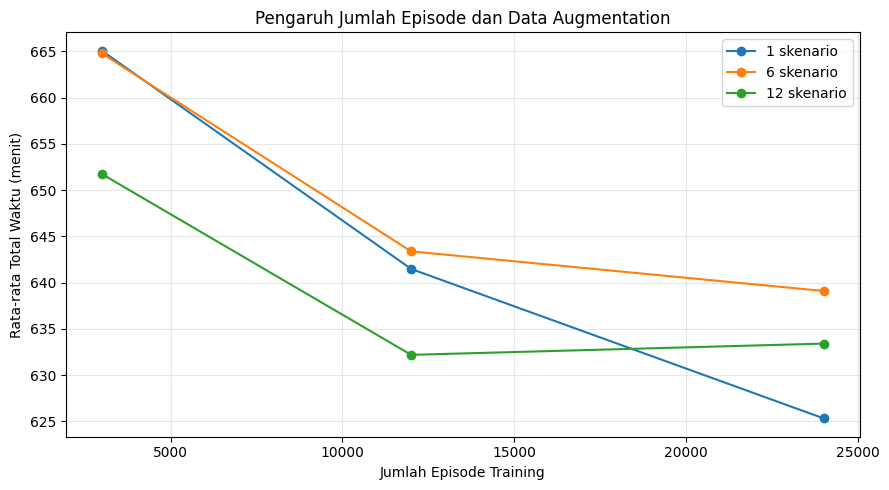

In [ ]:
plt.figure(figsize=(9, 5))

for jumlah_data in pilihan_skenario:

    data = df_ringkasan_tuning[
        df_ringkasan_tuning["jumlah_skenario"] == jumlah_data
    ].sort_values("episodes")

    plt.plot(
        data["episodes"],
        data["rata_total_menit"],
        marker="o",
        label=f"{jumlah_data} skenario"
    )

plt.xlabel("Jumlah Episode Training")
plt.ylabel("Rata-rata Total Waktu (menit)")
plt.title("Pengaruh Jumlah Episode dan Data Augmentation")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(folder_rl, "grafik_tuning_rl.png"),
    dpi=150
)

plt.show()

In [ ]:
# Konfigurasi kontrol: RL Normal, 12.000 episode
kontrol = df_ringkasan_tuning[
    (df_ringkasan_tuning["jumlah_skenario"] == 1) &
    (df_ringkasan_tuning["episodes"] == 12000)
].iloc[0]

# Konfigurasi dengan waktu terkecil
terbaik = df_ringkasan_tuning.iloc[0]

# Nearest Neighbor sebagai pembanding
hasil_nn = []

for cluster, matrices in matriks_kelompok.items():

    # Hanya gunakan data training untuk menentukan rute
    C_rata = matrices[:12].mean(axis=0)
    rute_nn = nearest_neighbor(C_rata)

    for idx in idx_validasi:

        waktu = hitung_waktu_rute(
            matrices[idx],
            rute_nn
        )

        hasil_nn.append({
            "kelompok_rute": cluster,
            "skenario": f"S{idx:02d}",
            "waktu_menit": waktu
        })

df_nn_validasi = pd.DataFrame(hasil_nn)

rata_nn = (
    df_nn_validasi.groupby("skenario")["waktu_menit"]
    .sum()
    .mean()
)

# Hitung perbaikan terhadap model kontrol
perbaikan_kontrol = (
    (kontrol["rata_total_menit"] - terbaik["rata_total_menit"])
    / kontrol["rata_total_menit"]
) * 100

# Hitung perbaikan terhadap NN
perbaikan_nn = (
    (rata_nn - terbaik["rata_total_menit"])
    / rata_nn
) * 100

print("=== HASIL TUNING ===")

print("Episode terbaik:", int(terbaik["episodes"]))
print("Jumlah skenario terbaik:", int(terbaik["jumlah_skenario"]))

print(
    "Rata-rata total waktu kontrol:",
    round(kontrol["rata_total_menit"], 2), "menit"
)

print(
    "Rata-rata total waktu hasil tuning:",
    round(terbaik["rata_total_menit"], 2), "menit"
)

print(
    "Rata-rata total waktu Nearest Neighbor:",
    round(rata_nn, 2), "menit"
)

print(
    "Perbaikan terhadap kontrol:",
    round(perbaikan_kontrol, 2), "%"
)

print(
    "Perbaikan terhadap Nearest Neighbor:",
    round(perbaikan_nn, 2), "%"
)

=== HASIL TUNING ===
Episode terbaik: 24000
Jumlah skenario terbaik: 1
Rata-rata total waktu kontrol: 641.48 menit
Rata-rata total waktu hasil tuning: 625.32 menit
Rata-rata total waktu Nearest Neighbor: 602.3 menit
Perbaikan terhadap kontrol: 2.52 %
Perbaikan terhadap Nearest Neighbor: -3.82 %
